# PPO (PureJaxRL) in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/ccr-9d70e555-krj2ct/examples/notebooks/ppo.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/ccr-9d70e555-krj2ct/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

A port of [PureJaxRL](https://github.com/luchris429/purejaxrl)'s `ppo.py` (PPO on CartPole) to
expex: [`examples/ppo/ppo.py`](../ppo/ppo.py). The original is nested `jax.lax.scan`s over
closures and `jax.vmap` with hand-written `in_axes`. The port keeps the algorithm, the
random-number stream and the arithmetic identical, but writes it as modules written for one
environment or one example (called on batches, which they map over) and plain Python `for`
loops and `if` statements, staged by `@expex.fn`.

This notebook trains it briefly, shows what expex reads from the annotations, checks it against
the original's saved run, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "ccr-9d70e555-krj2ct"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}", "optax")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO), "optax")
sys.path.insert(0, str(REPO / "examples" / "ppo"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import ppo  # examples/ppo/ppo.py
from ppo import Config, Net

print(inspect.getsource(ppo.gae))
print(inspect.getsource(ppo.Env.step))

@fn
def gae[T](
    reward: f32[T], value: f32[T], done: Bool[T], last_value: f32,
    gamma: float, lam: float,
) -> f32[T]:  # fmt: skip
    """Generalised advantage estimates for one environment's trajectory."""
    assert T >= 1
    advantage, next_value = jnp.float32(0), last_value
    out = []
    for t in reversed(range(reward.shape[0])):
        delta = reward[t] + gamma * next_value * (1 - done[t]) - value[t]
        advantage = delta + gamma * lam * (1 - done[t]) * advantage
        next_value = value[t]
        out.append(advantage)
    return jnp.asarray(out)[::-1]

    def step(self, key: Key, action: i32) -> tuple[f32[Obs], "Env", f32, Bool, Info]:
        """One step, starting a new episode when the current one ends."""
        _, reset_key = jr.split(key)
        reward = 1.0 - self.cart.terminal()  # based on the state before the step
        cart = self.cart.push(action)
        done = cart.terminal()

        episode_return = self.episode_return + reward
        epis

## The annotated signatures

Every typed function and method in the module, as expex reads it:

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(ppo):
    print(signature(report.fn))

Cart.new(key: Key) -> Cart
Cart.observe(self: Cart) -> f32[4]
Cart.terminal(self: Cart) -> Bool[()]
Cart.push(self: Cart, action: i32[()]) -> Cart
Env.reset(key: Key) -> tuple[f32[4], Env]
Env.step(self: Env, key: Key, action: i32[()]) -> tuple[f32[4], Env, f32[()], Bool[()], Info]
Layer.__call__(self: Layer, x: f32[I]) -> f32[O]
MLP.__call__(self: MLP, x: f32[I]) -> f32[O]
Net.__call__(self: Net, obs: f32[4]) -> tuple[f32[2], f32[()]]
Net.loss[M](self: Net, batch: Batch[Transition, M], advantage: f32[M], target: f32[M], cfg: Config) -> tuple[f32[()], tuple[f32[()], f32[()], f32[()]]]
gae[T](reward: f32[T], value: f32[T], done: Bool[T], last_value: f32[()], gamma: float, lam: float) -> f32[T]
train[H, T, N](key: Key, cfg: Config, net: Net[H] | None)


`expex.debug.shapes` shows the shape of every line of the loss, for all sizes at once:

In [4]:
print(expex.debug.shapes(Net.loss))

loss[M](self: Net, batch: Batch[Transition, M], advantage: f32[M], target: f32[M], cfg: Config) -> tuple[f32[()], tuple[f32[()], f32[()], f32[()]]]   [symbolic H, M; cfg=Config(lr=0.00025, num_envs=4, num_steps=128, num_updates=976, update_epochs=4, num_minibatches=4, gamma=0.99, gae_lambda=0.95, clip_eps=0.2, ent_coef=0.01, vf_coef=0.5, max_grad_norm=0.5, anneal_lr=True)]
  204 |     def loss[M](
  205 |         self, batch: Batch[Transition, M], advantage: f32[M], target: f32[M], cfg: Config
  206 |     ) -> tuple[f32, tuple[f32, f32, f32]]:
  207 |         """The PPO objective on a minibatch: clipped policy and value losses, entropy bonus."""
  208 |         logp_all, value = self(batch.obs)  # mapped over the M examples    # logp_all: f32[M, 2], value: f32[M]
  209 |         log_prob: f32[M] = jnp.sum(logp_all * jax.nn.one_hot(batch.action, 2), axis=-1)   # log_prob: f32[M]
  210 | 
  211 |         clipped = batch.value + (value - batch.value).clip(-cfg.clip_eps, cfg.clip_eps)   # 

## Run it

100 updates of 4 environments x 128 steps (the original runs 976): enough for the returns to
climb. The whole training run is one jitted call.

In [5]:
cfg = Config(num_updates=100)
start = time.perf_counter()
net, info = jax.jit(lambda k: ppo.train(k, cfg))(jr.key(30))
jax.block_until_ready(net)
print(f"trained in {time.perf_counter() - start:.1f} s (trace, compile and run)")

returns = jnp.where(info.returned_episode, info.returned_return, jnp.nan)
for lo in range(0, cfg.num_updates, 20):
    print(f"updates {lo:3d}-{lo + 19:3d}: mean episode return {jnp.nanmean(returns[lo : lo + 20]):6.1f}")

trained in 6.9 s (trace, compile and run)
updates   0- 19: mean episode return   39.7
updates  20- 39: mean episode return  143.6
updates  40- 59: mean episode return  208.4
updates  60- 79: mean episode return  222.1
updates  80- 99: mean episode return  203.6


Each Python loop in `train` was staged as a `lax.scan`, and the `if` in `Env.step` as a select:

In [6]:
for line, how in ppo.train.flow.items():
    print(f"line {line}: {how}")
print(ppo.Env.step.flow)

line 275: for -> lax.scan (carries env, key, net, obs, opt_state)
line 278: for -> lax.scan (carries env, key, obs)
line 303: for -> lax.scan (carries key, net, opt_state)
line 307: for -> lax.scan (carries net, opt_state)
{140: 'if -> lax.cond'}


## What the annotations give

**Proofs** for every size, without data:

In [7]:
expex.prove(ppo)

ok    ppo.Cart.new
ok    ppo.Cart.observe
ok    ppo.Cart.terminal
ok    ppo.Cart.push
ok    ppo.Env.reset
ok    ppo.Env.step
ok    ppo.Layer.__call__
ok    ppo.MLP.__call__
ok    ppo.Net.__call__
ok    ppo.Net.loss
ok    ppo.gae
ok    ppo.train

12 functions: 12 proved

**A summary** of the network, and its **cost** per observation:

In [8]:
expex.summary(net)

Net   (H=64)
module    class                                           params  formula    bytes   flops  flops formula
─────────────────────────────────────────────────────────────────────────────────────────────────────────
actor     MLP[I=4, H=64, O=2]                              4,610           18.4 kB  9.22 k  9218
  layers  tuple[Layer[4, H], Layer[H, H], Layer[H, 2]]     4,610           18.4 kB
critic    MLP[I=4, H=64, O=1]                              4,545           18.2 kB  9.09 k  9089
  layers  tuple[Layer[4, H], Layer[H, H], Layer[H, 1]]     4,545           18.2 kB
─────────────────────────────────────────────────────────────────────────────────────────────────────────
total     Net                                              9,155           36.6 kB  18.3 k  4·H² + 30·H + 15
note: FLOP formulas of actor, critic are in the call's sizes only: static fields differ from the class defaults

In [9]:
print(expex.cost(Net.__call__))

Net.__call__   (sizes: H)
  flops        4·H² + 30·H + 15
  parameters   2·H² + 15·H + 3
  largest      f32[H] (H elements)


**A diagram** of the network, drawn from the code (interactive when you run the notebook):

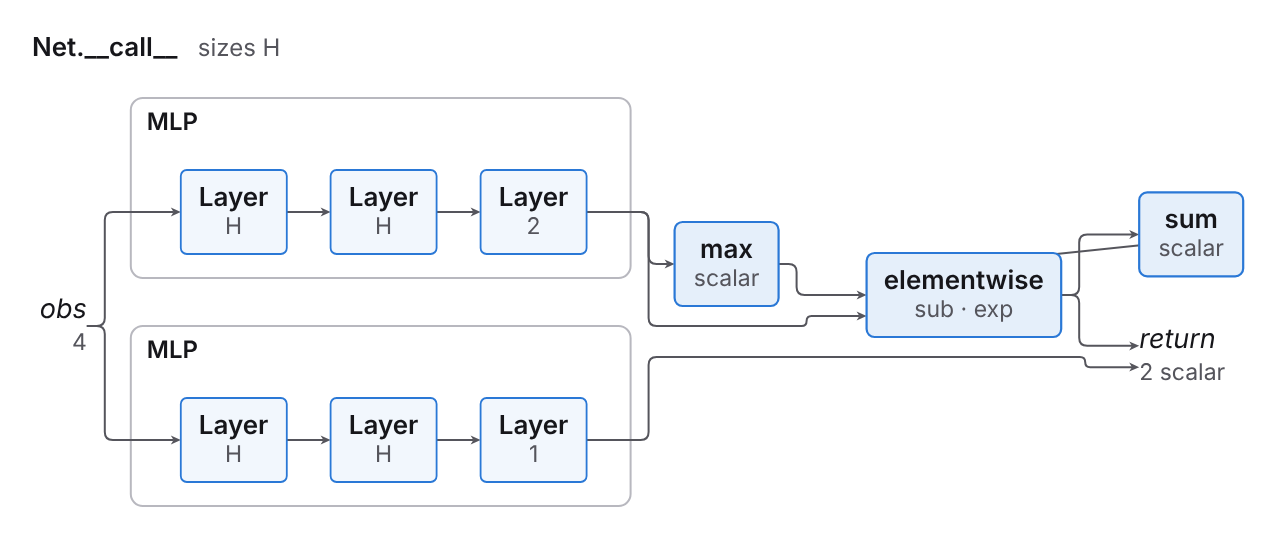

In [10]:
expex.diagram(Net.__call__, depth=2)

**`expex.inspect`**: every tool in one page, for the network on a batch of observations.

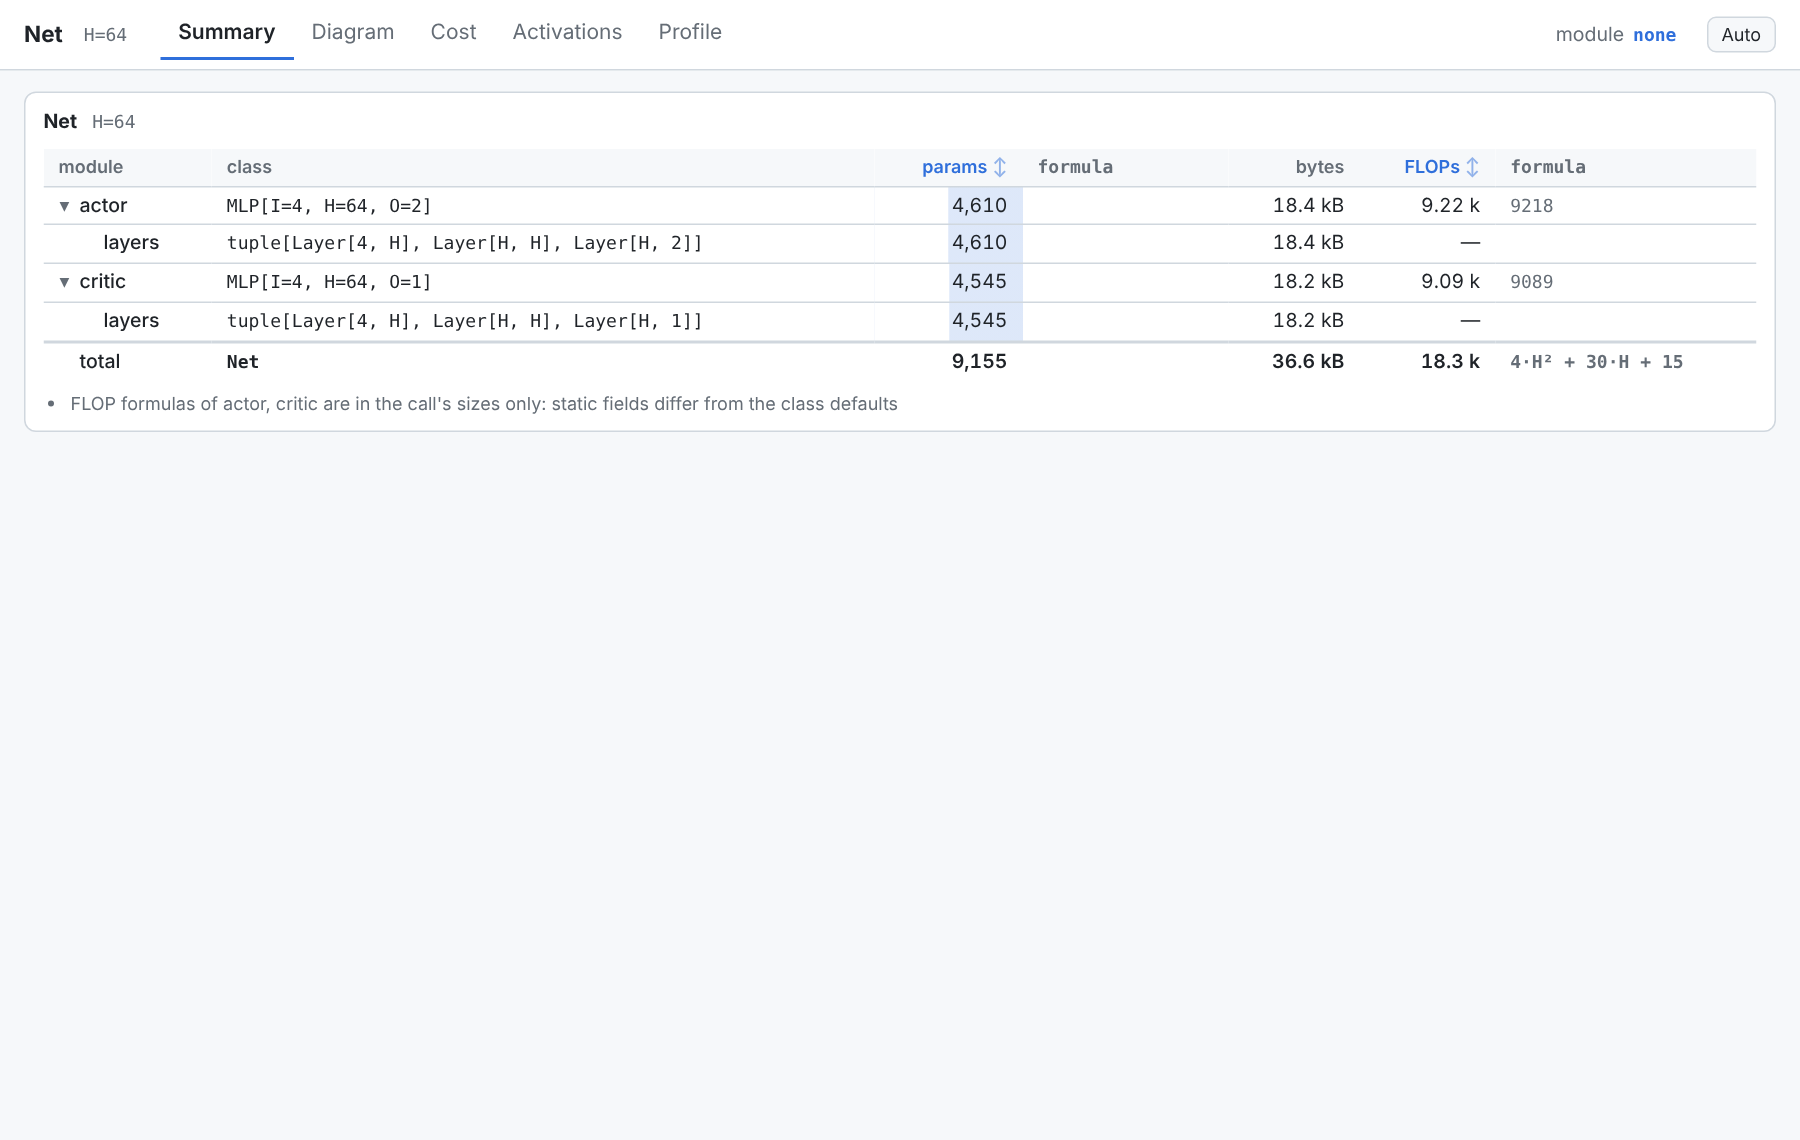

In [11]:
obs = jr.normal(jr.key(1), (16, 4))
expex.inspect(net, obs)

## A shape error

The network takes CartPole's 4 observations (`Obs = Literal[4]`); 5 are refused:

In [12]:
try:
    net(jnp.ones(5))
except expex.ShapeError as e:
    error = e
error

ShapeError: Net.__call__(): argument `obs` does not match its annotation.

    declared  obs: f32[4]
    received       f32[5]

    axis 0 should be 4, but is 5.

    __call__(self: Net, obs: f32[4]) -> tuple[f32[2], f32[()]]
    defined at examples/ppo/ppo.py:200
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


## Activations and gradients

`expex.debug.watch` of a stand-in loss on the observations (the PPO loss needs a batch of
transitions): each layer's outputs and the gradients reaching them.

In [13]:
def surrogate(net):
    logp, value = net(obs)
    return (value**2).mean() - logp.mean()


watch = expex.debug.watch(surrogate, net)
print(f"{len(watch.rows)} calls, {len(watch.flagged)} flagged")
watch

9 calls, 1 flagged


watch surrogate: loss 377.056, 9 calls, 1 flagged  (grad_ratio=100.0, growth=10.0)
                                                     ────────────────output────────────────  ─────────────d loss / d output──────────────
   call                           shape          ×n      mean    std  |max|    rms  nan/inf      mean      std    |max|      rms  nan/inf  flags
   Net.__call__                   (f32[2], f32)  16      5.35     10   20.2   11.4              0.785     1.16     2.52      1.4
     actor.__call__               f32[2]         16  5.23e-05   1.74   2.74   1.74           6.55e-11   0.0256    0.031   0.0256
       actor.layers[0].__call__   f32[64]        16    -0.019   0.43   1.56   0.43           5.22e-05  0.00439    0.014  0.00439
       actor.layers[1].__call__   f32[64]        16   -0.0132   0.84   2.62   0.84           -4.5e-06  0.00167  0.00412  0.00167
       actor.layers[2].__call__   f32[2]         16  5.23e-05   1.74   2.74   1.74           6.55e-11   0.0256    0.03

## Against the original

`tests/data/purejaxrl_ppo_3_updates.npz` holds the initial and final parameters and the episode
statistics of the unmodified PureJaxRL for 3 updates. From the same initial network and key,
the port gives the same numbers:

In [14]:
reference = np.load(REPO / "tests" / "data" / "purejaxrl_ppo_3_updates.npz")


def net_from(prefix):
    """A network holding the reference parameters (actor layers, then critic layers)."""
    leaves = []
    for i in range(6):
        leaves += [reference[f"{prefix}:params/Dense_{i}/kernel"], reference[f"{prefix}:params/Dense_{i}/bias"]]
    return jax.tree.unflatten(jax.tree.structure(Net(jr.key(0))), [jnp.asarray(x) for x in leaves])


cfg3 = Config(num_updates=3)
net3, info3 = jax.jit(lambda k, n: ppo.train(k, cfg3, n))(jr.PRNGKey(30), net_from("init"))
worst = max(float(jnp.abs(a - b).max()) for a, b in zip(jax.tree.leaves(net3), jax.tree.leaves(net_from("param"))))
print(f"final parameters: largest difference {worst:.2g}")
for field, key in [("returned_episode", "episode"), ("returned_length", "lengths"),
                   ("returned_return", "returns"), ("timestep", "timestep")]:  # fmt: skip
    print(f"{field:17} identical: {np.array_equal(np.asarray(getattr(info3, field)), reference[key])}")

final parameters: largest difference 3e-08
returned_episode  identical: True
returned_length   identical: True
returned_return   identical: True
timestep          identical: True


## Speed

Environment steps per second of the jitted training run (after compiling), at 4 environments.
Timings depend on the machine. The repository's [benchmarks/](../../benchmarks/) compare the
port with the original: about the same speed on CPU.

In [15]:
cfg = Config(num_updates=20)
run = jax.jit(lambda k: ppo.train(k, cfg))
jax.block_until_ready(run(jr.key(0)))  # compile
times = []
for i in range(3):
    start = time.perf_counter()
    jax.block_until_ready(run(jr.key(i)))
    times.append(time.perf_counter() - start)
steps = cfg.num_updates * cfg.num_steps * cfg.num_envs
print(f"{steps} environment steps (with the updates) in {np.median(times) * 1e3:.0f} ms: "
      f"{steps / np.median(times):,.0f} steps/s")  # fmt: skip

10240 environment steps (with the updates) in 70 ms: 146,604 steps/s
